# 108 - The Full SPXW Chain, Live

[Open in Colab](https://colab.research.google.com/github/userFRM/ThetaDataDx/blob/main/notebooks/108_full_chain_stream.ipynb)

One notebook, one Python process, one streaming session, loaded as far as a Pro plan allows:

- quotes on the 15,000 SPXW contracts nearest the money, across every listed expiration (the Pro limit for option quote streams),
- every option trade in the market, from the full trade stream, which also sends the quotes around each trade,
- quotes on the 2,000 most-traded stocks and ETFs (the Pro limit for stock quote streams),
- every stock trade in the market, from the full trade stream.

It runs for fifteen minutes, from 09:25 to 09:40 ET, across the opening bell, and reports every second of it: events per second on each stream, the busiest 100 ms, CPU and memory of the Python process, how far behind the notebook ran, and how many events were dropped. The machine it ran on is printed first, so you can compare with your own.

Each frame is decoded once, in Rust. The notebook reads the stream as Arrow record batches with `client.stream.batches()`, so Python handles a batch of rows at a time instead of one callback per event. There is no asyncio, no thread pool and no queue to manage here.

**Requires** a Pro plan on options and stocks during market hours, 09:30 - 16:00 ET: the full trade streams and the flat-file report used to rank stocks are Pro. On Standard, set `QUOTE_LIMIT` to 10,000 and `STOCK_QUOTES` to 1,000, pick the stocks yourself, and subscribe to per-contract trades as in [107](107_full_trade_stream.ipynb). One live session per account: a second session on the same account takes over the connection, so stop any other streaming client first.

In [1]:
# In Colab or a fresh environment this installs the SDK first.
import importlib.util
if importlib.util.find_spec("thetadatadx") is None:
    %pip install -q "thetadatadx-py[all]" matplotlib psutil

In [2]:
import os
import platform
import sys
import time
from collections import Counter, defaultdict
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import psutil
import pyarrow
import pyarrow.compute as pc
import thetadatadx
from IPython.display import Markdown, display

from thetadatadx import Client, Config, Contract, Credentials, SecType

cpu_model = platform.processor() or platform.machine()
if os.path.exists("/proc/cpuinfo"):
    cpu_model = next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")), cpu_model)
print(f"machine      {cpu_model}, {os.cpu_count()} logical cores, {psutil.virtual_memory().total / 2**30:.1f} GiB RAM")
print(f"system       {platform.platform()}")
print(f"python       {sys.version.split()[0]}")
print(f"thetadatadx  {thetadatadx.__version__}, pyarrow {pyarrow.__version__}")

machine      Intel(R) Xeon(R) CPU @ 2.20GHz, 2 logical cores, 12.7 GiB RAM
system       Linux-6.6.159+-x86_64-with-glibc2.39
python       3.13.18
thetadatadx  0.9.0, pyarrow 23.0.1


## 1. Connect

Credentials come from `THETADATA_API_KEY` or `creds.txt` when either is there. Otherwise, as in Colab, the cell asks for your email and password in hidden prompts, so neither is saved in the notebook. `wait_mode = "backoff"` keeps the event-ring consumer spinning while events flow and lets it sleep when the stream goes quiet, so an idle session does not hold a whole core.

In [3]:
import os
from getpass import getpass

if os.environ.get("THETADATA_API_KEY") or os.path.exists("creds.txt"):
    creds = Credentials.from_env_or_file("creds.txt")
else:
    creds = Credentials(getpass("ThetaData email: "), getpass("ThetaData password: "))

config = Config.production()
config.wait_mode = "backoff"
client = Client(creds, config)
print(client)

ThetaData email: ··········
ThetaData password: ··········
Client(market_data=connected, streaming=none)


## 2. The SPXW chain

One call lists every SPXW contract quoted today. SPX trades near ten times SPY, which is close enough to rank strikes by distance from the money; the quote streams go to the nearest ones first.

In [4]:
QUOTE_LIMIT = 15_000  # option quote streams: 15,000 on Pro, 10,000 on Standard

today = datetime.now(ZoneInfo("America/New_York")).date()
spy = client.market_data.stock_snapshot_quote(["SPY"]).to_list()[0]
spot = 10 * (spy.bid + spy.ask) / 2

listed = client.market_data.option_list_contracts("quote", today, symbol="SPXW").to_list()
listed = [c for c in listed if c.expiration >= int(today.strftime("%Y%m%d"))]
listed.sort(key=lambda c: abs(c.strike - spot))
chain = [
    Contract.option("SPXW", expiration=str(c.expiration), strike=f"{c.strike:g}", right=c.right)
    for c in listed
]

print(f"SPX near {spot:,.0f}")
print(f"{len(chain):,} SPXW contracts across {len({c.expiration for c in listed})} expirations")
print(f"quotes on the nearest {len(chain[:QUOTE_LIMIT]):,}")

SPX near 7,186
20,620 SPXW contracts across 38 expirations
quotes on the nearest 15,000


## 3. The most-traded stocks

The flat-file end-of-day report covers every stock in one call. Ranking it by the number of trades in the last session picks the names whose quotes move the most.

In [5]:
STOCK_QUOTES = 2_000  # stock quote streams: 2,000 on Pro, 1,000 on Standard

for back in range(1, 6):  # the last session with a report
    eod = client.market_data.stock_flat_file_eod(today - pd.offsets.BDay(back)).to_pandas()
    if len(eod):
        break
stocks = eod.nlargest(STOCK_QUOTES, "count")["symbol"].tolist()

print(f"{len(eod):,} stocks in the report for {eod['date'].iloc[0]}")
print(f"quotes on the {len(stocks):,} most traded, starting with {', '.join(stocks[:10])}")

subscriptions = (
    [c.quote() for c in chain[:QUOTE_LIMIT]]
    + [Contract.stock(s).quote() for s in stocks]
    + [SecType.OPTION.full_trades(), SecType.STOCK.full_trades()]
)
print(f"{len(subscriptions):,} subscriptions")

18,587 stocks in the report for 20261120
quotes on the 2,000 most traded, starting with NVDA, SOXL, ANT, QQQ, MU, SNDK, SPY, AMD, SPCX, TQQQ
17,002 subscriptions


## 4. Wait for the window

The run starts at `START_ET` New York time and lasts `RUN_SECONDS`. Set `START_ET = None` to start at once.

In [6]:
START_ET = "09:25"   # 09:25 ET = 5 minutes before the opening bell
RUN_SECONDS = 900    # 15 minutes

if START_ET:
    start_at = datetime.combine(today, datetime.strptime(START_ET, "%H:%M").time(), ZoneInfo("America/New_York"))
    wait = (start_at - datetime.now(ZoneInfo("America/New_York"))).total_seconds()
    if wait > 0:
        print(f"waiting {wait / 60:.1f} min, until {START_ET} ET")
        time.sleep(wait)
print(f"starting at {datetime.now(ZoneInfo('America/New_York')):%H:%M:%S} ET")

waiting 19.3 min, until 09:25 ET
starting at 09:25:00 ET


## 5. Subscribe and run

`batches()` opens the session, so the reader comes first and the subscriptions after it. A batch is handed to Python when it reaches `batch_size` rows or when `linger_ms` has passed since its first row, whichever comes first. When the market is quiet a batch is small and still arrives within 10 ms; when it is busy a batch carries thousands of rows.

For every batch the notebook counts rows per stream, per second and per 100 ms, counts rows per stock and per SPXW expiration, and records the delay from the moment the SDK received the oldest row (`received_at_ns`) to the moment Python holds it. Once a second it also records the CPU time and memory of the whole Python process, the SDK's event ring and the dropped-event count. The panel refreshes once a second.

In [7]:
per_second = defaultdict(Counter)   # wall-clock second -> rows per stream
per_100ms = Counter()               # 100 ms window, by SDK receive time -> rows
delay_ms = defaultdict(float)       # wall-clock second -> worst receive-to-notebook delay
batch_count = Counter()             # wall-clock second -> batches handed to Python
health = {}                         # wall-clock second -> CPU, memory, event ring, dropped
by_symbol, by_expiration = Counter(), Counter()
process = psutil.Process()
ring_peak = ring_second = 0
panel = display(Markdown("Connecting..."), display_id=True)


def show(elapsed, second):
    total = sum(sum(c.values()) for c in per_second.values())
    h = health.get(second, {})
    panel.update(Markdown(
        f"| running | events | last second | CPU, last second | memory | worst delay, last second | event ring peak | dropped |\n"
        f"|---|---|---|---|---|---|---|---|\n"
        f"| {elapsed:.0f} of {RUN_SECONDS} s | {total:,} | {sum(per_second.get(second, Counter()).values()):,}/s "
        f"| {h.get('cpu %', 0):.0f}% | {h.get('memory MiB', 0):,.0f} MiB | {delay_ms.get(second, 0):.1f} ms "
        f"| {ring_peak:,} | {h.get('dropped', 0):,} |"
    ))


start = time.monotonic()
last_cpu, last_tick, last_second = time.process_time(), start, int(time.time())
with client.stream.batches(batch_size=32_768, linger_ms=10) as batches:
    client.stream.subscribe_many(subscriptions)
    active = len(client.stream.active_subscriptions()) + len(client.stream.active_full_subscriptions())
    for batch in batches:
        second = int(time.time())
        asset = pc.if_else(pc.is_valid(batch["expiration"]), "option", "stock")  # only option rows carry an expiration
        stream = pc.binary_join_element_wise(asset, batch["event_type"], " ")
        for row in pc.value_counts(stream).to_pylist():
            per_second[second][row["values"]] += row["counts"]
        for row in pc.value_counts(pc.divide(batch["received_at_ns"], pyarrow.scalar(100_000_000, pyarrow.uint64()))).to_pylist():
            per_100ms[row["values"]] += row["counts"]
        for row in pc.value_counts(batch["symbol"]).to_pylist():
            by_symbol[row["values"]] += row["counts"]
        for row in pc.value_counts(batch["expiration"]).to_pylist():
            if row["values"] is not None:
                by_expiration[row["values"]] += row["counts"]
        oldest = pc.min(batch["received_at_ns"]).as_py()
        delay_ms[second] = max(delay_ms[second], (time.time_ns() - oldest) / 1e6)
        batch_count[second] += 1
        ring_second = max(ring_second, client.stream.ring_occupancy())

        if second != last_second:  # once a second: process health for the second that just ended
            now, cpu = time.monotonic(), time.process_time()
            health[last_second] = {
                "cpu %": 100 * (cpu - last_cpu) / (now - last_tick),
                "memory MiB": process.memory_info().rss / 2**20,
                "event ring": ring_second,
                "dropped": client.stream.dropped_event_count(),
            }
            ring_peak = max(ring_peak, ring_second)
            show(now - start, last_second)
            last_cpu, last_tick, last_second, ring_second = cpu, now, second, 0
            if now - start >= RUN_SECONDS:
                break

    elapsed = time.monotonic() - start
    dropped = client.stream.dropped_event_count()
    ring_size = client.stream.ring_capacity()
print(f"Session closed after {elapsed:.0f} s.")

| running | events | last second | CPU, last second | memory | worst delay, last second | event ring peak | dropped |
|---|---|---|---|---|---|---|---|
| 901 of 900 s | 58,602,222 | 118,391/s | 81% | 310 MiB | 35.7 ms | 62,786 | 0 |

Session closed after 901 s.


## 6. What came in

In [8]:
ET = "America/New_York"
rates = pd.DataFrame.from_dict(per_second, orient="index").fillna(0).astype(int).sort_index()
seconds = pd.DataFrame.from_dict(health, orient="index").join(pd.Series(delay_ms, name="worst delay ms")).join(pd.Series(batch_count, name="batches"))
table = rates.join(seconds, how="inner").iloc[1:-1]  # drop the partial first and last seconds
table.index = pd.to_datetime(table.index, unit="s", utc=True).tz_convert(ET)
table.index.name = "second (ET)"
streams = sorted(rates.columns)
table["all streams"] = table[streams].sum(axis=1)
table.to_csv("108_per_second.csv")

summary = pd.DataFrame({
    "events": table[streams].sum(),
    "mean per second": table[streams].mean().round(0),
    "busiest second": table[streams].max(),
}).astype(int).sort_values("events", ascending=False)
summary.loc["all streams"] = [int(table["all streams"].sum()), int(table["all streams"].mean()), int(table["all streams"].max())]
display(summary)

busiest_100ms, rows_100ms = max(per_100ms.items(), key=lambda kv: kv[1])
busiest_at = pd.Timestamp(busiest_100ms * 100_000_000, unit="ns", tz="UTC").tz_convert(ET)
print(f"active subscriptions        {active:,}")
print(f"run                         {table.index[0]:%H:%M:%S} to {table.index[-1]:%H:%M:%S} ET, {len(table):,} full seconds")
print(f"busiest 100 ms              {rows_100ms:,} events at {busiest_at.strftime('%H:%M:%S.%f')[:-3]} ET, a rate of {rows_100ms * 10:,}/s")
print(f"batches handed to Python    {int(table['batches'].sum()):,}, {table['all streams'].sum() / table['batches'].sum():,.0f} rows each on average")
print(f"worst delay, median second  {table['worst delay ms'].median():.1f} ms")
print(f"worst delay, 99th pct       {table['worst delay ms'].quantile(0.99):.1f} ms")
print(f"worst delay, worst second   {table['worst delay ms'].max():.1f} ms")
print(f"process CPU, mean           {table['cpu %'].mean():.0f}% of one core")
print(f"process CPU, busiest second {table['cpu %'].max():.0f}% of one core")
print(f"memory, peak                {table['memory MiB'].max():,.0f} MiB")
print(f"event ring peak             {ring_peak:,} of {ring_size:,} slots")
print(f"dropped events              {dropped:,}")

,events,mean per second,busiest second
stock quote,27952465,31162,229682
option quote,23420908,26110,132662
stock trade,6030476,6723,162262
option trade,956561,1066,6289
option ohlcvc,98256,110,2695
stock ohlcvc,12512,14,2338
all streams,58471178,65185,405914


active subscriptions        17,002
run                         09:25:03 to 09:39:59 ET, 897 full seconds
busiest 100 ms              57,839 events at 09:30:06.900 ET, a rate of 578,390/s
batches handed to Python    62,124, 941 rows each on average
worst delay, median second  17.6 ms
worst delay, 99th pct       40.8 ms
worst delay, worst second   293.9 ms
process CPU, mean           73% of one core
process CPU, busiest second 156% of one core
memory, peak                310 MiB
event ring peak             62,786 of 131,072 slots
dropped events              0


Minute by minute:

In [9]:
minutes = table[streams + ["all streams"]].resample("1min").sum()
minutes["CPU %, mean"] = table["cpu %"].resample("1min").mean().round(0)
minutes["worst delay ms"] = table["worst delay ms"].resample("1min").max().round(1)
minutes.index = minutes.index.strftime("%H:%M")
display(minutes)

,option ohlcvc,option quote,option trade,stock ohlcvc,stock quote,stock trade,all streams,"CPU %, mean",worst delay ms
second (ET),,,,,,,,,
09:25,0,2741,0,1415,252719,48308,305183,37.0,16.4
09:26,0,0,0,451,255738,44244,300433,38.0,17.1
09:27,0,14416,0,404,265655,48622,329097,38.0,19.1
09:28,0,0,0,402,254923,46155,301480,37.0,19.2
09:29,0,0,0,554,312436,54905,367895,39.0,15.9
09:30,47563,1782811,170683,8835,3851307,1730681,7591880,93.0,293.9
09:31,9751,1271541,99520,35,2276981,510692,4168520,82.0,34.0
09:32,7566,2039854,91591,49,2172008,468212,4779280,87.0,37.2
09:33,5882,1965227,80572,77,2044318,448922,4544998,85.0,35.7


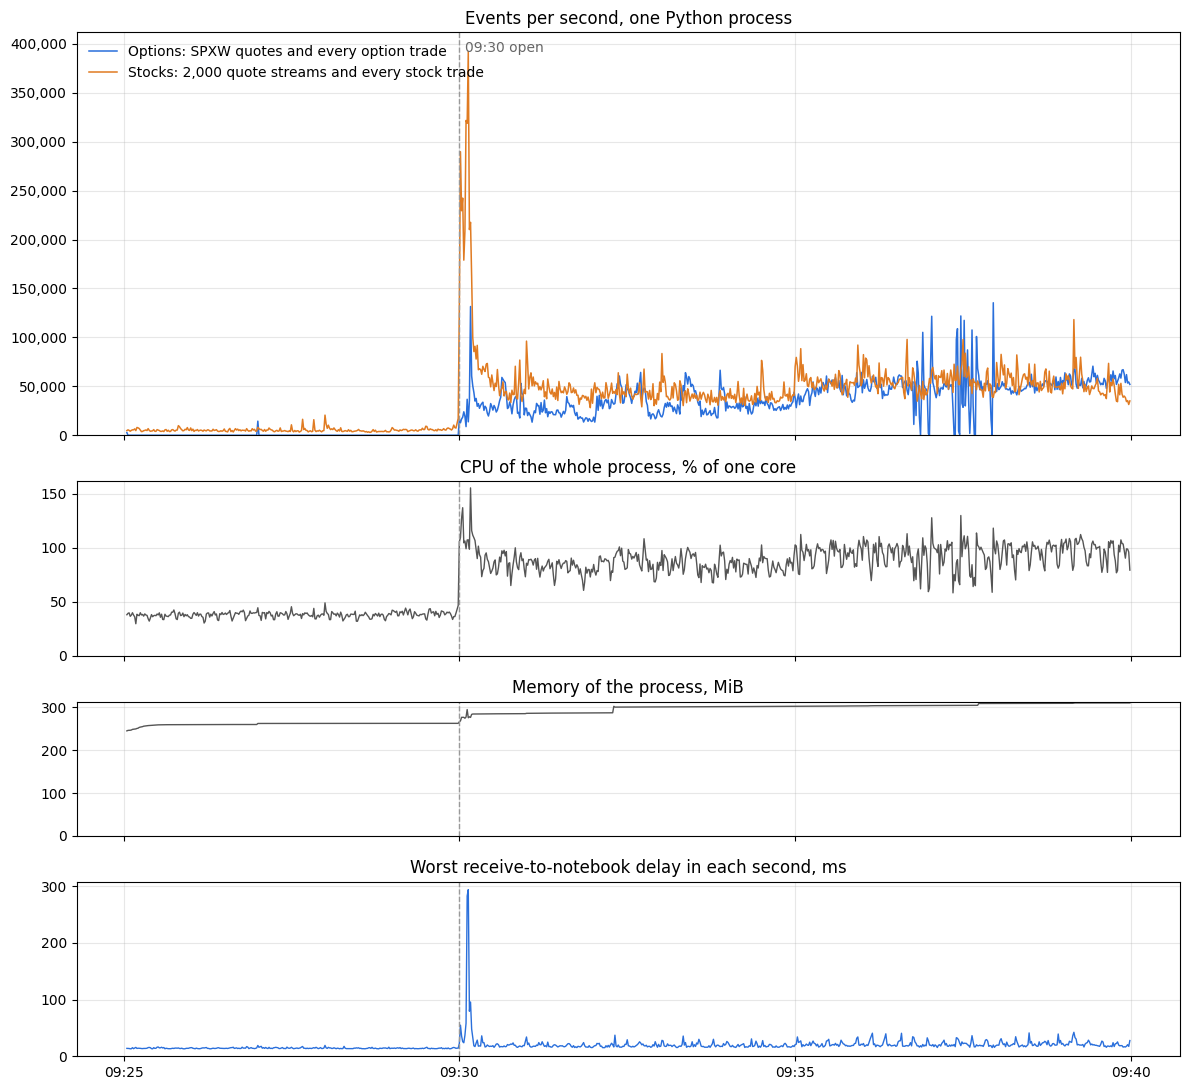

In [10]:
options = table[[c for c in streams if c.startswith("option")]].sum(axis=1)
stock = table[[c for c in streams if c.startswith("stock")]].sum(axis=1)
bell = table.index[0].replace(hour=9, minute=30, second=0)

fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True, height_ratios=[3, 1.3, 1, 1.3])
axes[0].plot(options.index, options, color="#2a6fdb", linewidth=1.1, label="Options: SPXW quotes and every option trade")
axes[0].plot(stock.index, stock, color="#e07b22", linewidth=1.1, label="Stocks: 2,000 quote streams and every stock trade")
axes[0].set_title("Events per second, one Python process")
axes[0].legend(frameon=False, loc="upper left")
axes[1].plot(table.index, table["cpu %"], color="#555555", linewidth=1.0)
axes[1].set_title("CPU of the whole process, % of one core")
axes[2].plot(table.index, table["memory MiB"], color="#555555", linewidth=1.0)
axes[2].set_title("Memory of the process, MiB")
axes[3].plot(table.index, table["worst delay ms"], color="#2a6fdb", linewidth=1.0)
axes[3].set_title("Worst receive-to-notebook delay in each second, ms")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
    if table.index[0] <= bell <= table.index[-1]:
        ax.axvline(bell, color="#999999", linestyle="--", linewidth=1)
if table.index[0] <= bell <= table.index[-1]:
    axes[0].annotate("09:30 open", (bell, 1), xycoords=("data", "axes fraction"), xytext=(4, -14), textcoords="offset points", color="#666666")
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=table.index.tz))
plt.tight_layout()
plt.show()

Where the events came from:

In [11]:
top_stocks = pd.Series({s: n for s, n in by_symbol.items() if s != "SPXW"}).nlargest(15)
top_expirations = pd.Series(by_expiration).nlargest(10)
top_expirations.index = pd.to_datetime(top_expirations.index.astype(str)).strftime("%Y-%m-%d")
display(pd.DataFrame({"stock": top_stocks.index, "events": top_stocks.values}),
        pd.DataFrame({"SPXW expiration": top_expirations.index, "events": top_expirations.values}))
print("Every second of the run is in 108_per_second.csv.")

,stock,events
0,NVDA,2970883
1,SPY,960768
2,QQQ,875288
3,SOXL,824217
4,TQQQ,570093
5,SOXX,523281
6,ANT,481414
7,VOO,402002
8,TSLA,394321
9,NVDL,391946


,SPXW expiration,events
0,2026-11-23,5679018
1,2026-11-27,2548574
2,2026-11-25,1961823
3,2026-11-30,1897268
4,2026-11-24,1865829
5,2026-12-18,1104540
6,2026-12-04,741482
7,2027-01-15,719904
8,2026-12-31,617454
9,2026-12-11,510097


Every second of the run is in 108_per_second.csv.


---

To react to each event as it arrives instead, register a callback with `client.streaming(on_event)`, as in [105](105_realtime_streaming.ipynb).

**Previous:** [107 - Full Trade Stream](107_full_trade_stream.ipynb)
**Back to start:** [101 - Getting Started](101_getting_started.ipynb)